In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\AI-MSU")
RAW_DIR = PROJECT_DIR / "data" / "raw"

def find_file(filename):
    files = list(RAW_DIR.rglob(filename))
    if not files:
        raise FileNotFoundError(filename + " not found")
    return files[0]

logon = pd.read_csv(find_file("logon.csv"), nrows=50000)
print("Sample shape:", logon.shape)
display(logon.head())

Sample shape: (50000, 5)


,id,date,user,pc,activity
0,{X1D9-S0ES98JV-5357PWMI},01/02/2010 06:49:00,NGF0157,PC-6056,Logon
1,{G2B3-L6EJ61GT-2222RKSO},01/02/2010 06:50:00,LRR0148,PC-4275,Logon
2,{U6Q3-U0WE70UA-3770UREL},01/02/2010 06:53:04,LRR0148,PC-4124,Logon
3,{I0N5-R7NA26TG-6263KNGM},01/02/2010 07:00:00,IRM0931,PC-7188,Logon
4,{D1S0-N6FH62BT-5398KANK},01/02/2010 07:00:00,MOH0273,PC-6699,Logon


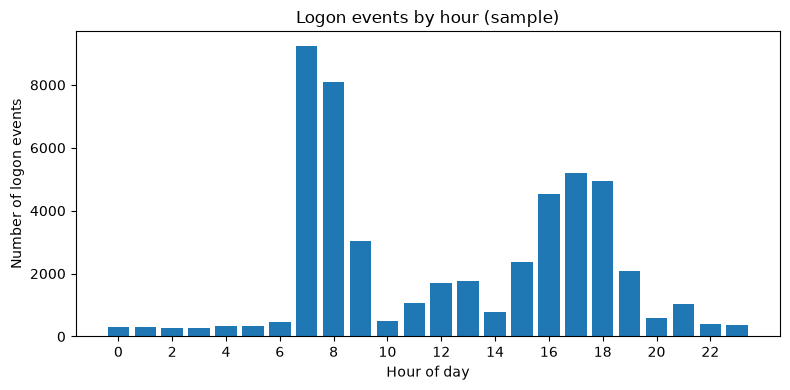

In [2]:
date_col = "date" if "date" in logon.columns else None
if date_col:
    logon[date_col] = pd.to_datetime(logon[date_col], errors="coerce")
    logon = logon.dropna(subset=[date_col])
    logon["hour"] = logon[date_col].dt.hour
    hourly = logon["hour"].value_counts().sort_index()
    plt.figure(figsize=(8, 4))
    plt.bar(hourly.index, hourly.values)
    plt.xlabel("Hour of day")
    plt.ylabel("Number of logon events")
    plt.title("Logon events by hour (sample)")
    plt.xticks(range(0, 24, 2))
    plt.tight_layout()
    plt.show()
else:
    print("No date column found. Check the column names printed above.")

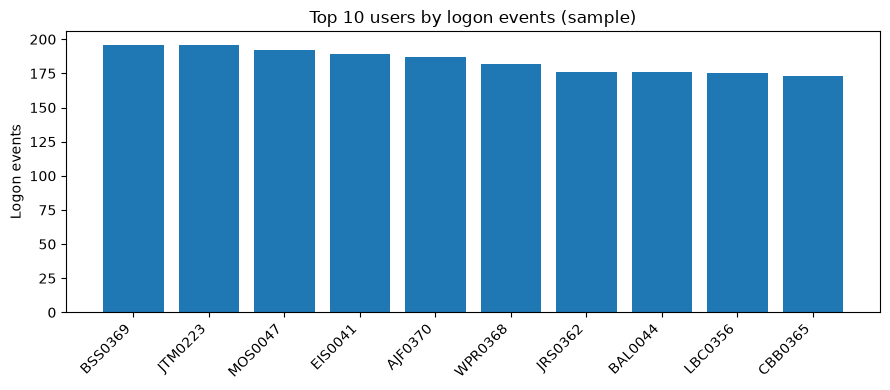

In [3]:
if "user" in logon.columns:
    top_users = logon["user"].value_counts().head(10)
    plt.figure(figsize=(9, 4))
    plt.bar(top_users.index.astype(str), top_users.values)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Logon events")
    plt.title("Top 10 users by logon events (sample)")
    plt.tight_layout()
    plt.show()